
[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
First Five Records:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mea

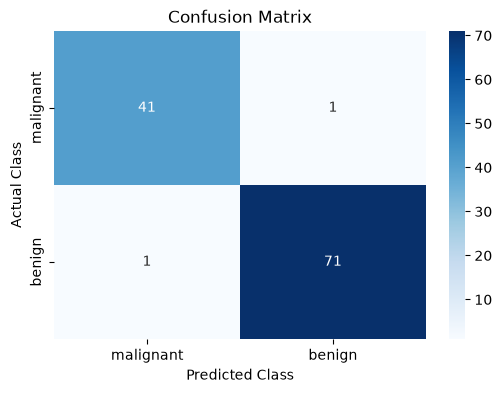

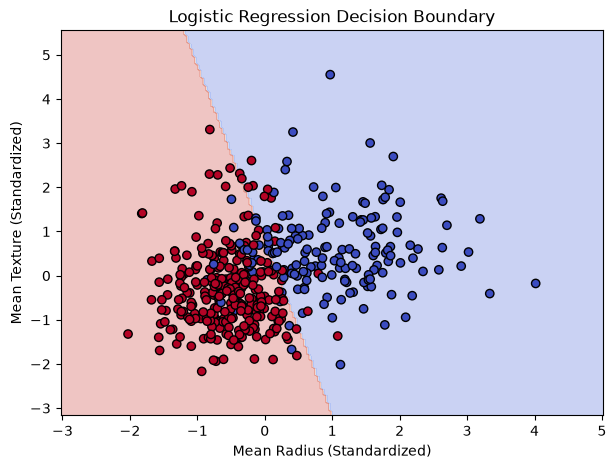

In [1]:

# Experiment 6: Binary Classification using Logistic Regression

# Step 1: Install required libraries
%pip install numpy pandas matplotlib seaborn scikit-learn

# Step 2: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Step 3: Load the Breast Cancer dataset
dataset = load_breast_cancer()

X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
y = dataset.target

print("First Five Records:")
print(X.head())

# Step 4: Display dataset information
print("\nDataset Shape:")
print(X.shape)

print("\nFeature Names:")
print(X.columns.tolist())

print("\nTarget Classes:")
print(dataset.target_names)

print("\nDataset Information:")
X.info()

print("\nSummary Statistics:")
print(X.describe())

# Step 5: Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

# Step 6: Standardize numerical features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 7: Train Logistic Regression model
model = LogisticRegression(max_iter=10000)
model.fit(X_train_scaled, y_train)

# Step 8: Predict classes for test data
y_pred = model.predict(X_test_scaled)

print("\nFirst 10 Actual Classes:")
print(y_test[:10])

print("\nFirst 10 Predicted Classes:")
print(y_pred[:10])

# Step 9: Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# Step 10: Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("\nModel Evaluation Metrics:")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)

# Step 11: Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=dataset.target_names))

# Step 12: Visualize confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=dataset.target_names,
    yticklabels=dataset.target_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix")
plt.show()

# Step 13: Display decision boundary using two selected features
# This is a 2-feature demonstration, not the full 30-feature model.

X_2 = X[["mean radius", "mean texture"]]

X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(
    X_2, y, test_size=0.2, random_state=42, stratify=y
)

scaler_2 = StandardScaler()
X_train_2_scaled = scaler_2.fit_transform(X_train_2)

boundary_model = LogisticRegression(max_iter=10000)
boundary_model.fit(X_train_2_scaled, y_train_2)

x_min, x_max = X_train_2_scaled[:, 0].min() - 1, X_train_2_scaled[:, 0].max() + 1
y_min, y_max = X_train_2_scaled[:, 1].min() - 1, X_train_2_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]
Z = boundary_model.predict(grid)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
plt.scatter(
    X_train_2_scaled[:, 0],
    X_train_2_scaled[:, 1],
    c=y_train_2,
    edgecolors="black",
    cmap="coolwarm"
)

plt.xlabel("Mean Radius (Standardized)")
plt.ylabel("Mean Texture (Standardized)")
plt.title("Logistic Regression Decision Boundary")
plt.show()
